In [54]:
import glob
import os
import re
import pandas as pd

files = sorted(glob.glob(os.path.join("DATA/OUTPUT", "MHW_summary_table_wide_*.csv")))

dfs = []
for f in files:
    df = pd.read_csv(f)
    match = re.search(r"_(\d+m)_bathymetry", os.path.basename(f))
    df["bathymetry"] = match.group(1) if match else None
    dfs.append(df)

combined = pd.concat(dfs, ignore_index=True)

print(f"Loaded {len(files)} files, {len(combined)} rows")
print(combined["bathymetry"].value_counts())

combined.sample(10)

Loaded 5 files, 675 rows
bathymetry
1000m    135
200m     135
400m     135
600m     135
800m     135
Name: count, dtype: int64


,Year,Zone,activity_degC_days_m2,mean_area_km2,mean_duration_days,mean_intensity_degC,mean_n_events,number_of_events,sum_area_km2,bathymetry
589,1997,S,5.134548e+11,32.606215,11.192308,1.413192,4.727273,52.0,1695.523203,800m
460,1999,S,2.364868e+10,32.696932,6.000000,1.368016,0.625000,5.0,163.484662,600m
649,2017,S,1.130552e+12,32.282228,19.576923,1.666828,4.727273,52.0,1678.675846,800m
636,2013,NW,7.079440e+11,79.351209,13.115385,1.717844,1.625000,52.0,4126.262855,800m
262,2023,S,6.138983e+11,33.146081,23.000000,1.535044,5.500000,33.0,1093.820689,200m
52,1998,S,4.191232e+11,29.616280,13.238095,1.121056,2.800000,42.0,1243.883767,1000m
667,2023,S,1.394168e+12,32.079251,29.983333,1.419671,5.454545,60.0,1924.755054,800m
373,2015,S,4.540973e+11,33.059707,21.192308,1.717510,4.333333,26.0,859.552373,400m
288,1987,NW,6.594252e+10,73.674015,5.692308,1.467363,0.448276,13.0,957.762197,400m
316,1996,S,1.764503e+11,33.146081,7.761905,1.572756,3.500000,21.0,696.067711,400m


In [55]:
import numpy as np
from plotnine import *

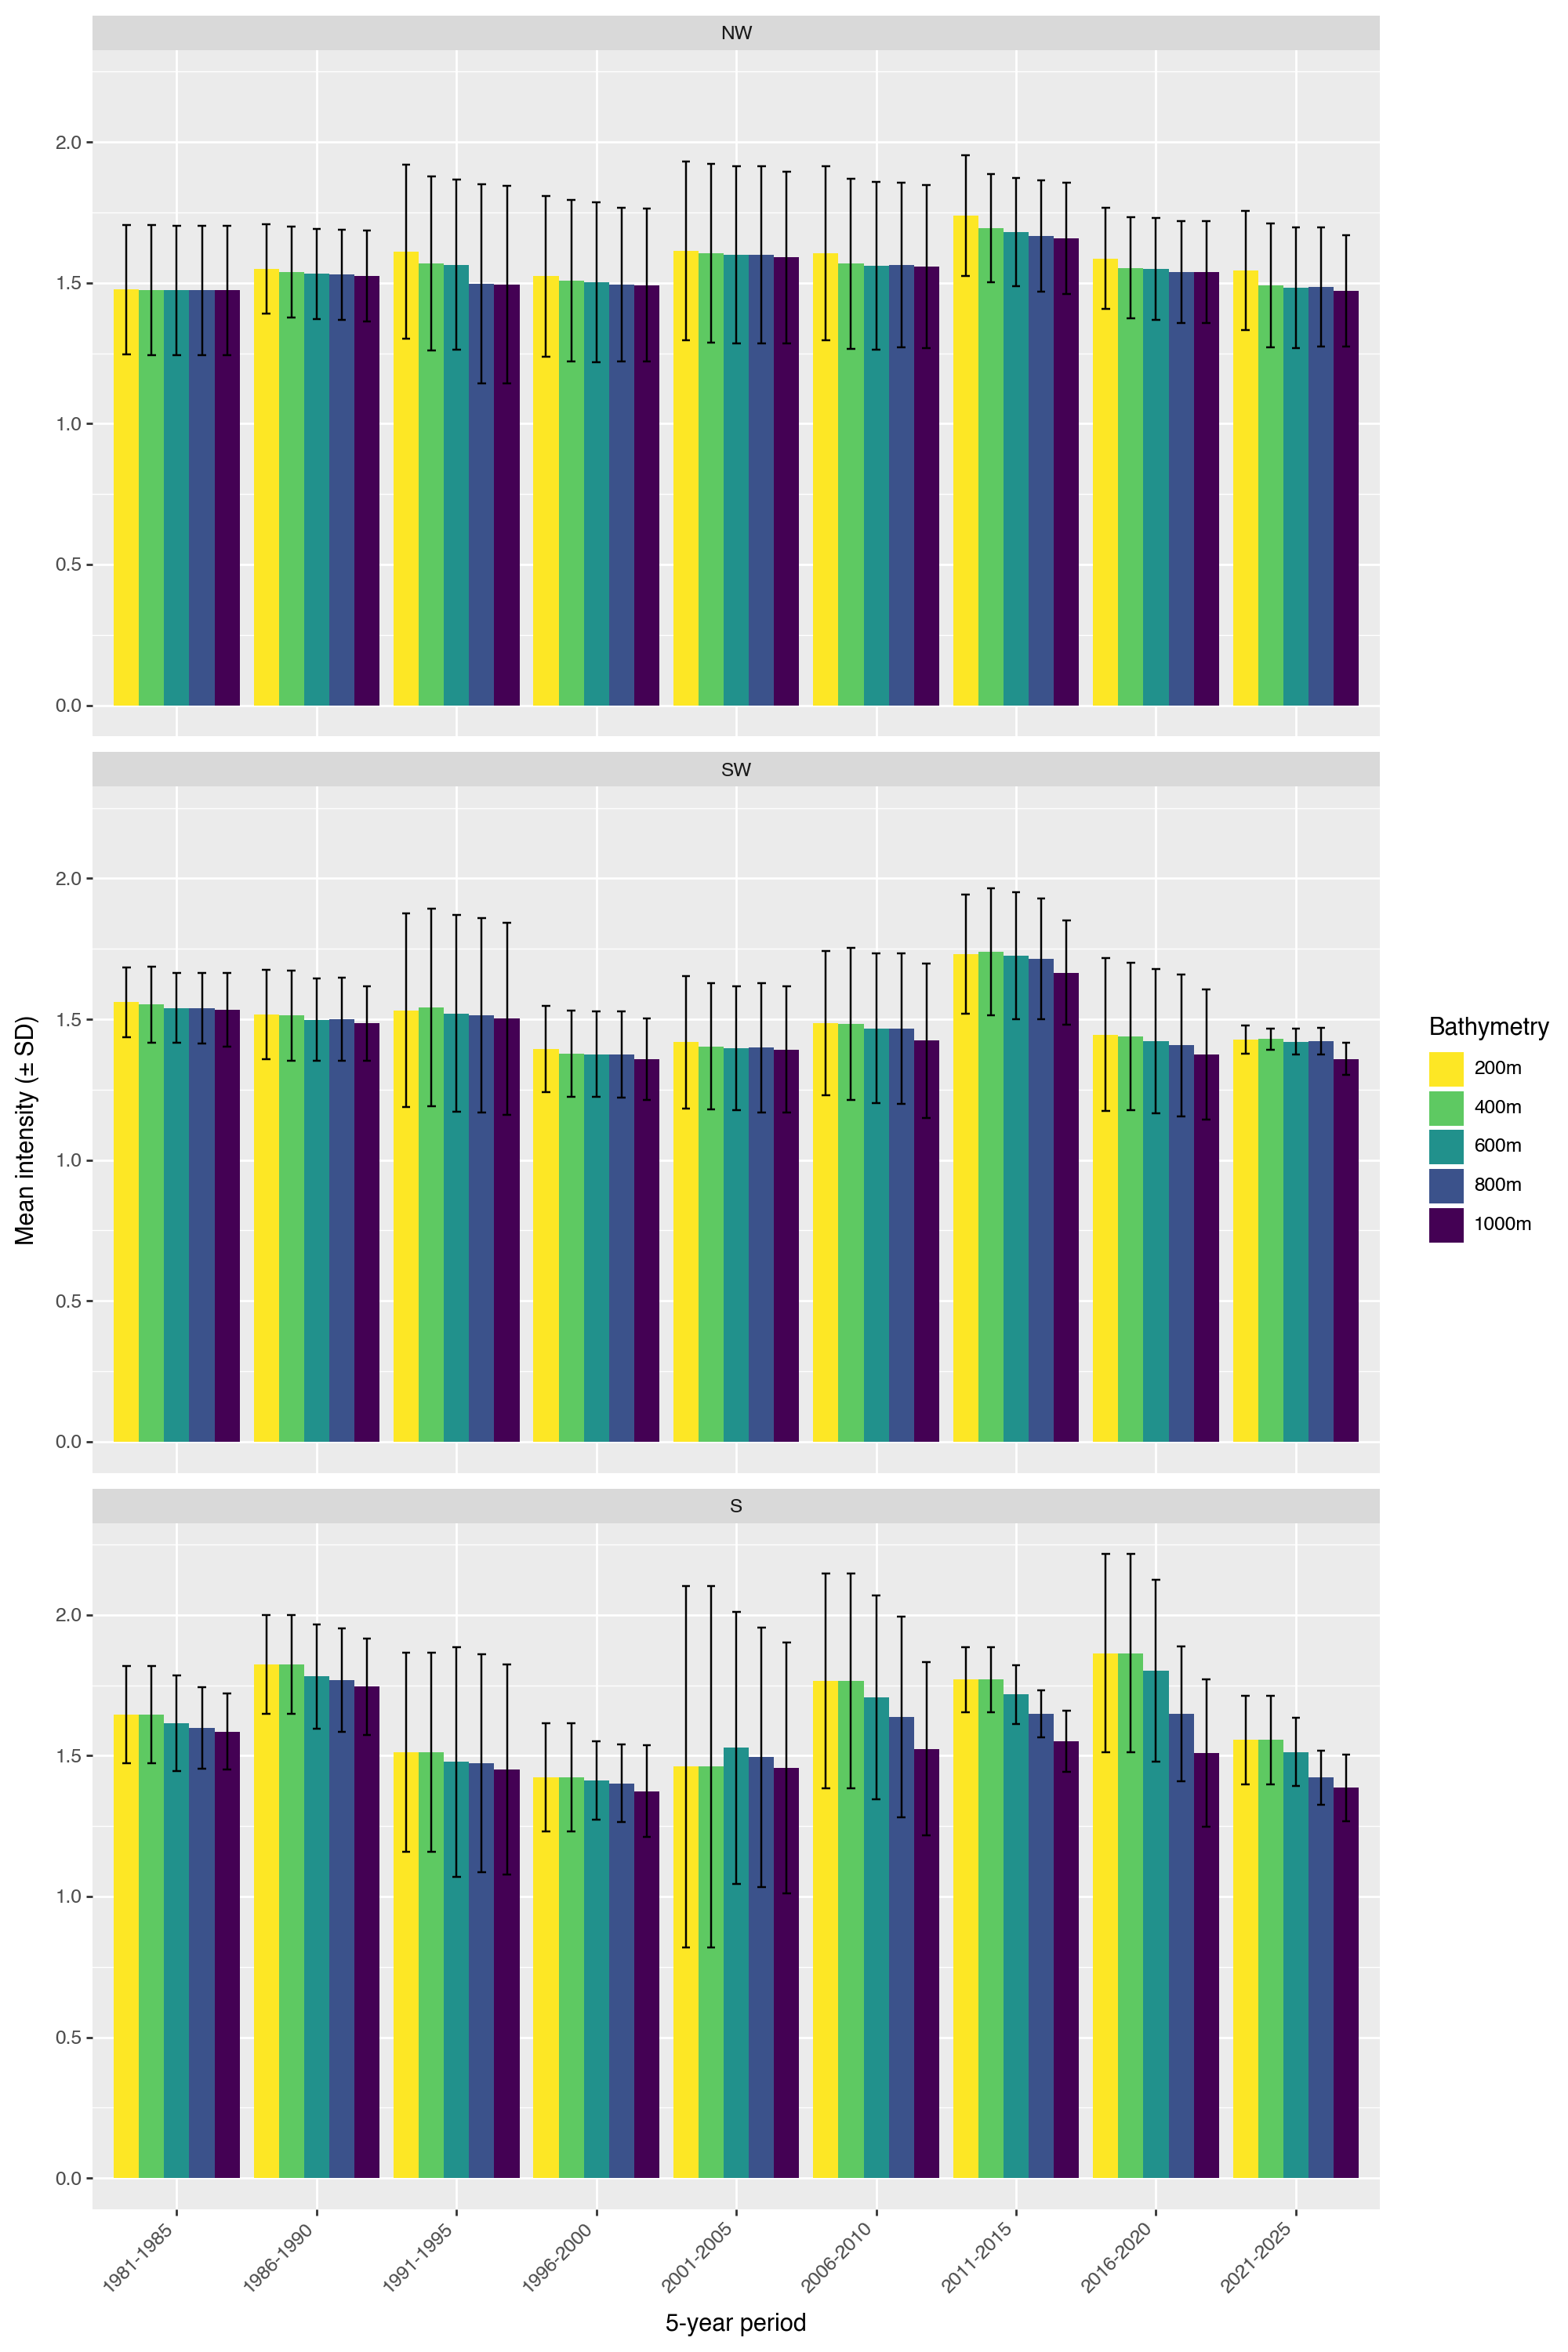

In [56]:
from plotnine import (
    ggplot, aes, geom_col, geom_errorbar, position_dodge, facet_wrap,
    scale_fill_cmap_d, labs, theme, element_text
)

# Choose what to plot
var = "mean_intensity_degC"
var_label = "Mean intensity"
zones = ["NW", "SW", "S"]

# 5-year bins ending in 2025: 1981–1985, 1986–1990, ..., 2021–2025
combined["half_decade_start"] = ((combined["Year"] - 1) // 5) * 5 + 1
combined["half_decade"] = (
    combined["half_decade_start"].astype(str) + "-" + (combined["half_decade_start"] + 4).astype(str)
)

# Mean and SD per zone, bin and bathymetry
half_dec = (
    combined[combined["Zone"].isin(zones)]
    .groupby(["Zone", "half_decade_start", "half_decade", "bathymetry"], as_index=False)
    .agg(mean=(var, "mean"), sd=(var, "std"))
    .sort_values("half_decade_start")
)

# Panel order (NW, SW, S) and bathymetry in ascending depth order
half_dec["Zone"] = pd.Categorical(half_dec["Zone"], categories=zones, ordered=True)
depth_order = sorted(half_dec["bathymetry"].unique(), key=lambda d: int(d.rstrip("m")))
half_dec["bathymetry"] = pd.Categorical(half_dec["bathymetry"], categories=depth_order, ordered=True)

# Plot
dodge = position_dodge(width=0.9)

(
    ggplot(half_dec, aes(x="half_decade", y="mean", fill="bathymetry"))
    + geom_col(position=dodge)
    + geom_errorbar(aes(ymin="mean - sd", ymax="mean + sd"), position=dodge, width=0.3)
    + facet_wrap("~Zone", nrow=3)
    + scale_fill_cmap_d("viridis_r")
    + labs(x="5-year period", y=f"{var_label} (± SD)", fill="Bathymetry")
    + theme(
        axis_text_x=element_text(rotation=45, ha="right"),
        figure_size=(10, 15),
    )
)

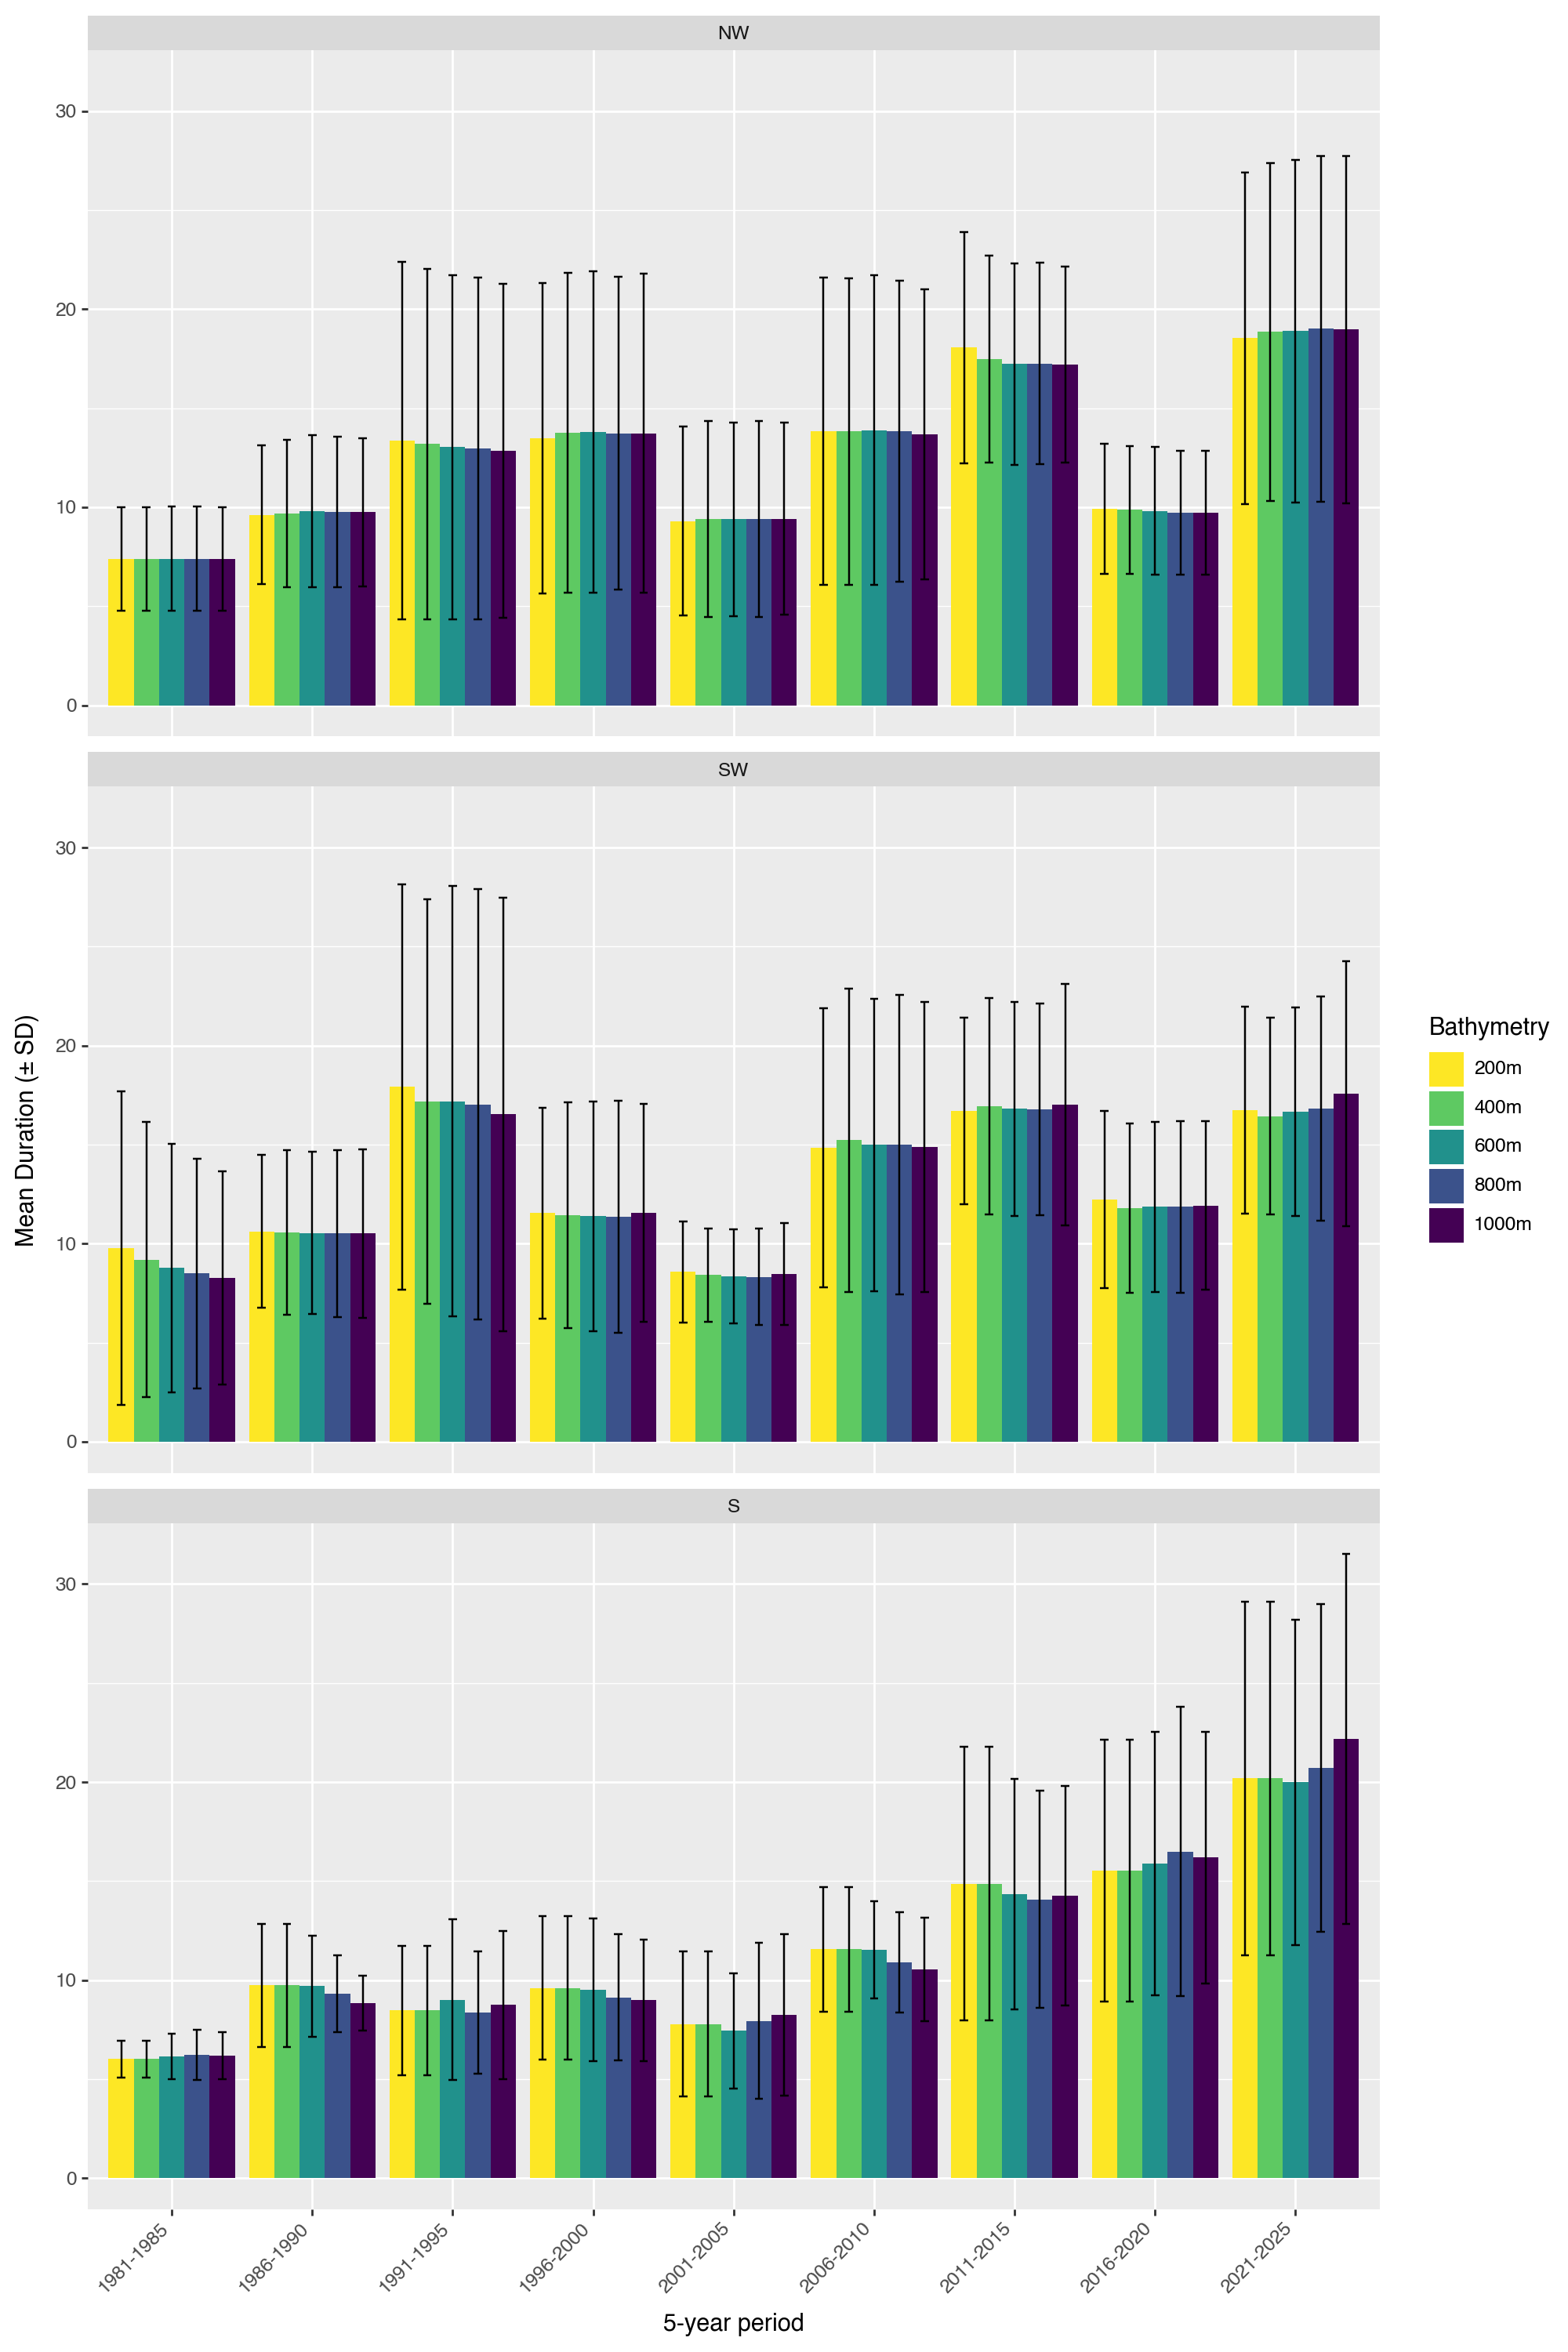

In [57]:
from plotnine import (
    ggplot, aes, geom_col, geom_errorbar, position_dodge, facet_wrap,
    scale_fill_cmap_d, labs, theme, element_text
)

# Choose what to plot
var = "mean_duration_days"
var_label = "Mean Duration"
zones = ["NW", "SW", "S"]

# 5-year bins ending in 2025: 1981–1985, 1986–1990, ..., 2021–2025
combined["half_decade_start"] = ((combined["Year"] - 1) // 5) * 5 + 1
combined["half_decade"] = (
    combined["half_decade_start"].astype(str) + "-" + (combined["half_decade_start"] + 4).astype(str)
)

# Mean and SD per zone, bin and bathymetry
half_dec = (
    combined[combined["Zone"].isin(zones)]
    .groupby(["Zone", "half_decade_start", "half_decade", "bathymetry"], as_index=False)
    .agg(mean=(var, "mean"), sd=(var, "std"))
    .sort_values("half_decade_start")
)

# Panel order (NW, SW, S) and bathymetry in ascending depth order
half_dec["Zone"] = pd.Categorical(half_dec["Zone"], categories=zones, ordered=True)
depth_order = sorted(half_dec["bathymetry"].unique(), key=lambda d: int(d.rstrip("m")))
half_dec["bathymetry"] = pd.Categorical(half_dec["bathymetry"], categories=depth_order, ordered=True)

# Plot
dodge = position_dodge(width=0.9)

(
    ggplot(half_dec, aes(x="half_decade", y="mean", fill="bathymetry"))
    + geom_col(position=dodge)
    + geom_errorbar(aes(ymin="mean - sd", ymax="mean + sd"), position=dodge, width=0.3)
    + facet_wrap("~Zone", nrow=3)
    + scale_fill_cmap_d("viridis_r")
    + labs(x="5-year period", y=f"{var_label} (± SD)", fill="Bathymetry")
    + theme(
        axis_text_x=element_text(rotation=45, ha="right"),
        figure_size=(10, 15),
    )
)

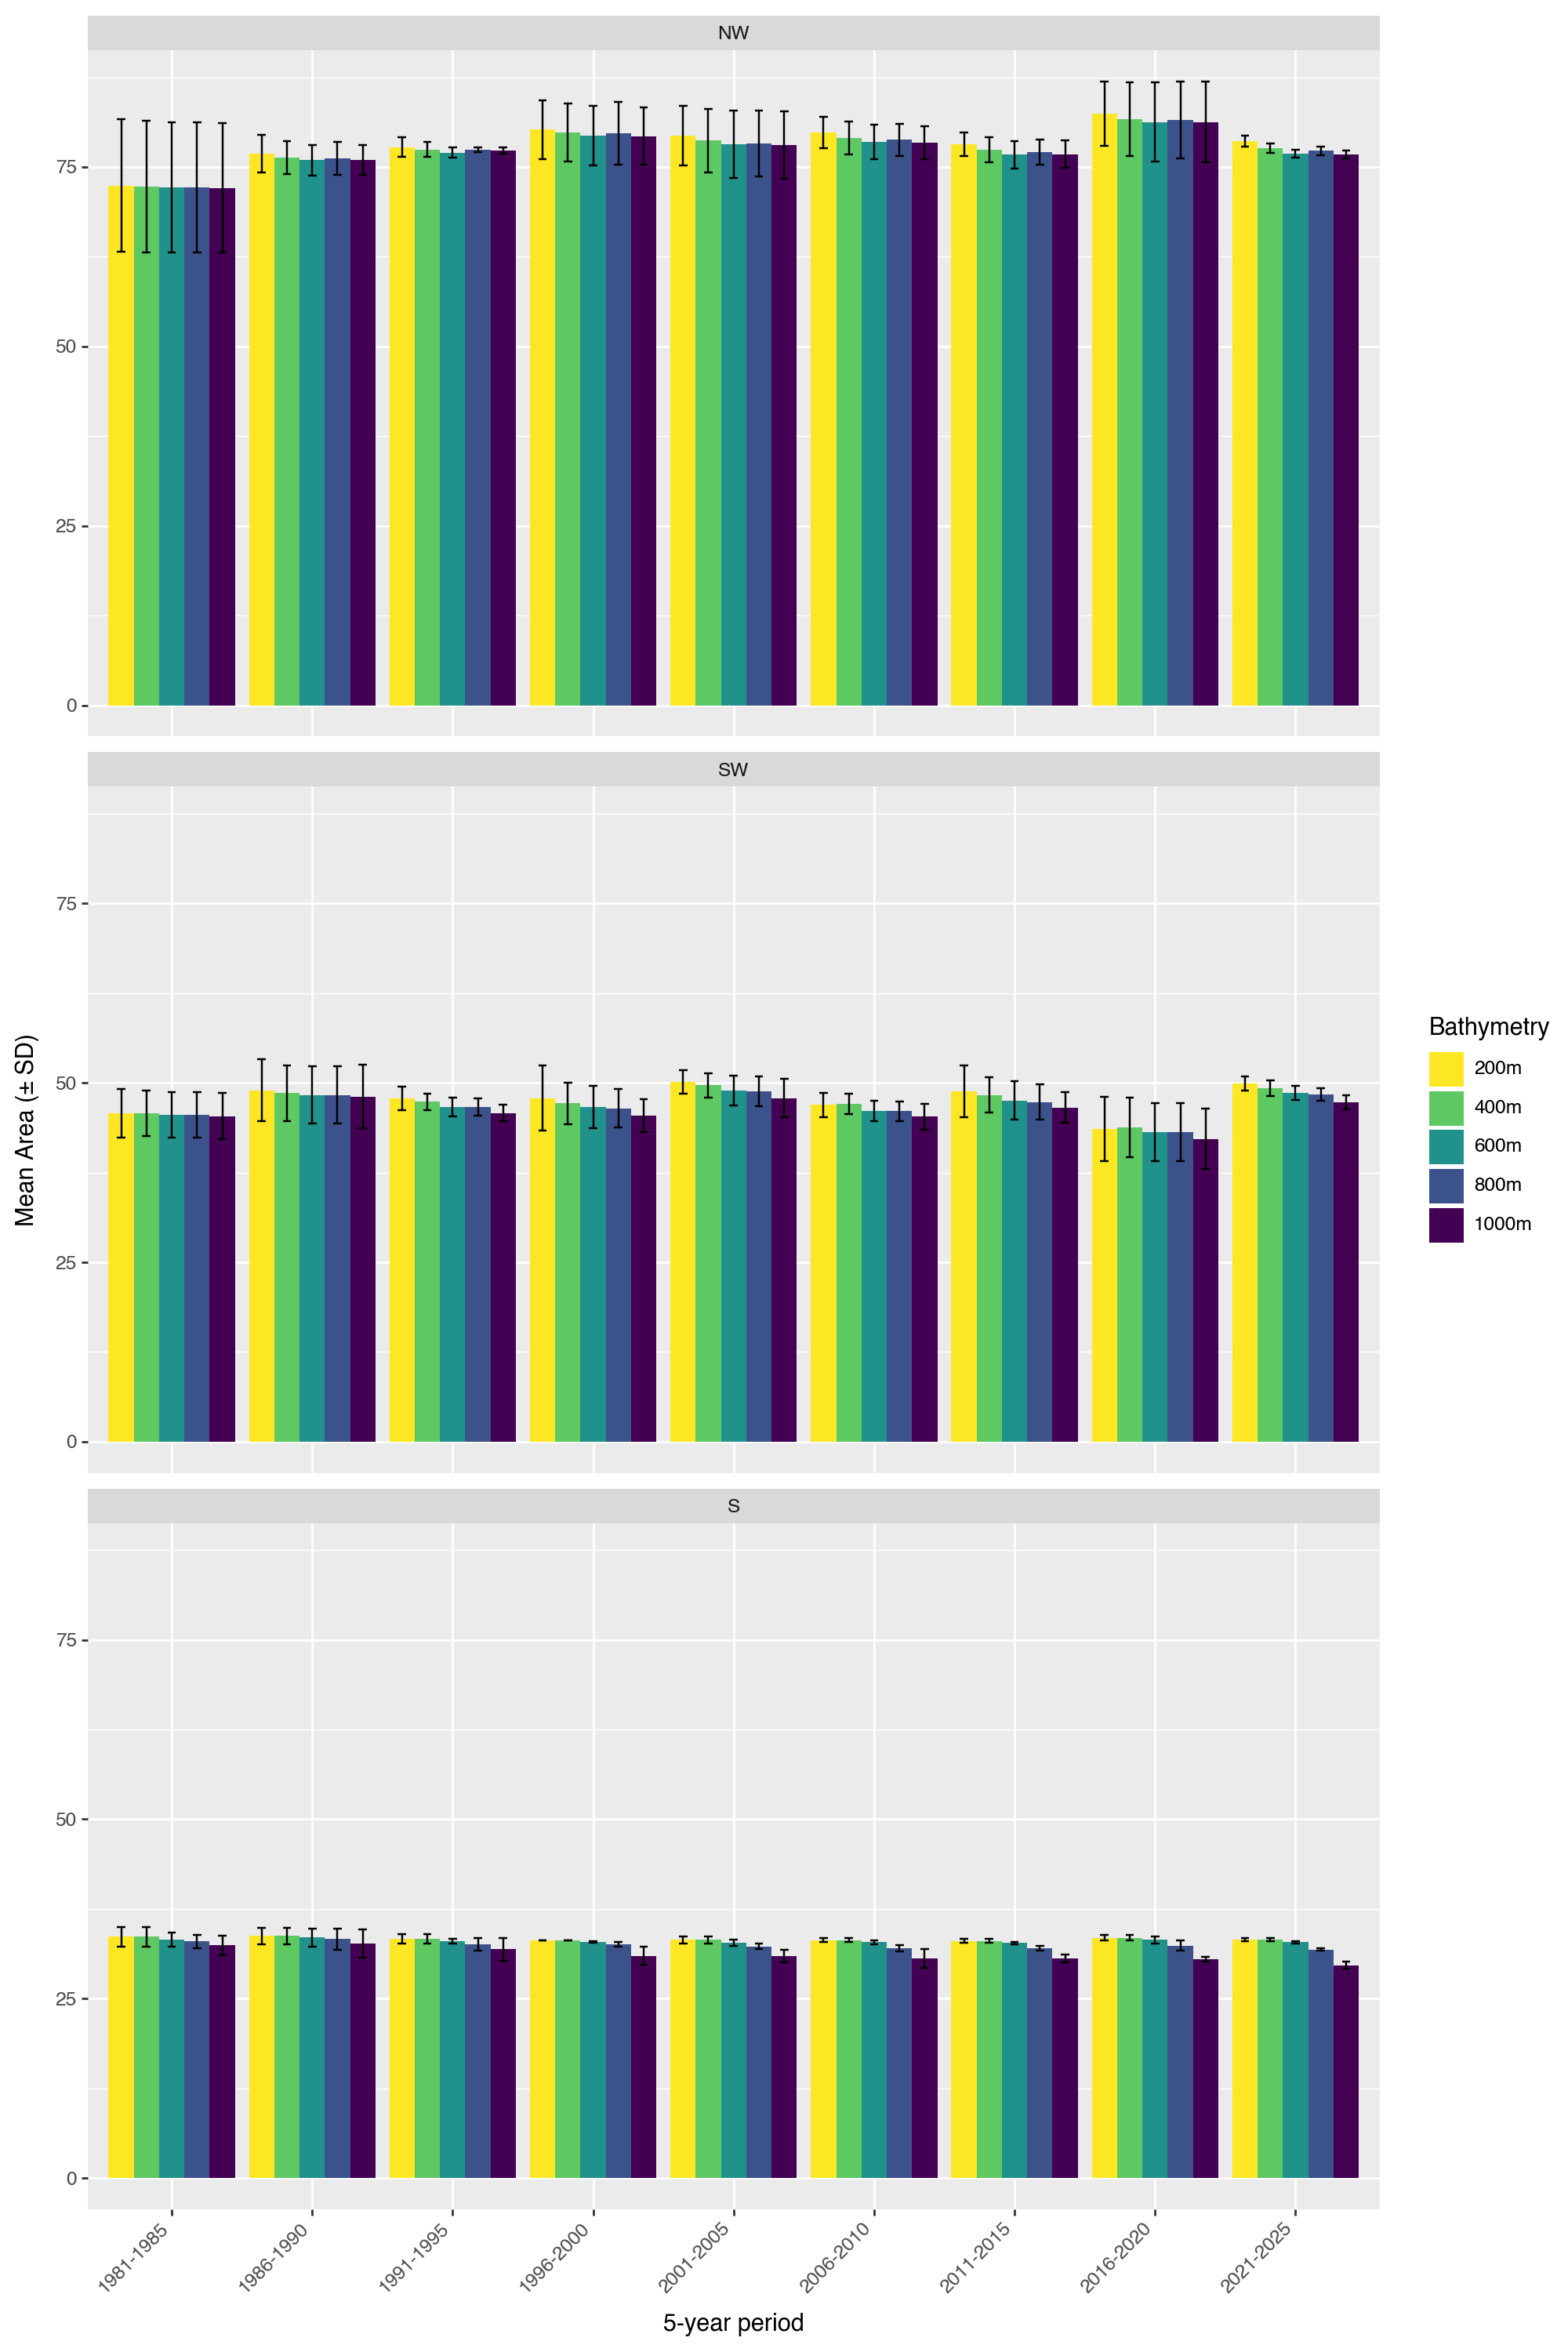

In [58]:
from plotnine import (
    ggplot, aes, geom_col, geom_errorbar, position_dodge, facet_wrap,
    scale_fill_cmap_d, labs, theme, element_text
)

# Choose what to plot
var = "mean_area_km2"
var_label = "Mean Area"
zones = ["NW", "SW", "S"]

# 5-year bins ending in 2025: 1981–1985, 1986–1990, ..., 2021–2025
combined["half_decade_start"] = ((combined["Year"] - 1) // 5) * 5 + 1
combined["half_decade"] = (
    combined["half_decade_start"].astype(str) + "-" + (combined["half_decade_start"] + 4).astype(str)
)

# Mean and SD per zone, bin and bathymetry
half_dec = (
    combined[combined["Zone"].isin(zones)]
    .groupby(["Zone", "half_decade_start", "half_decade", "bathymetry"], as_index=False)
    .agg(mean=(var, "mean"), sd=(var, "std"))
    .sort_values("half_decade_start")
)

# Panel order (NW, SW, S) and bathymetry in ascending depth order
half_dec["Zone"] = pd.Categorical(half_dec["Zone"], categories=zones, ordered=True)
depth_order = sorted(half_dec["bathymetry"].unique(), key=lambda d: int(d.rstrip("m")))
half_dec["bathymetry"] = pd.Categorical(half_dec["bathymetry"], categories=depth_order, ordered=True)

# Plot
dodge = position_dodge(width=0.9)

(
    ggplot(half_dec, aes(x="half_decade", y="mean", fill="bathymetry"))
    + geom_col(position=dodge)
    + geom_errorbar(aes(ymin="mean - sd", ymax="mean + sd"), position=dodge, width=0.3)
    + facet_wrap("~Zone", nrow=3)
    + scale_fill_cmap_d("viridis_r")
    + labs(x="5-year period", y=f"{var_label} (± SD)", fill="Bathymetry")
    + theme(
        axis_text_x=element_text(rotation=45, ha="right"),
        figure_size=(10, 15),
    )
)

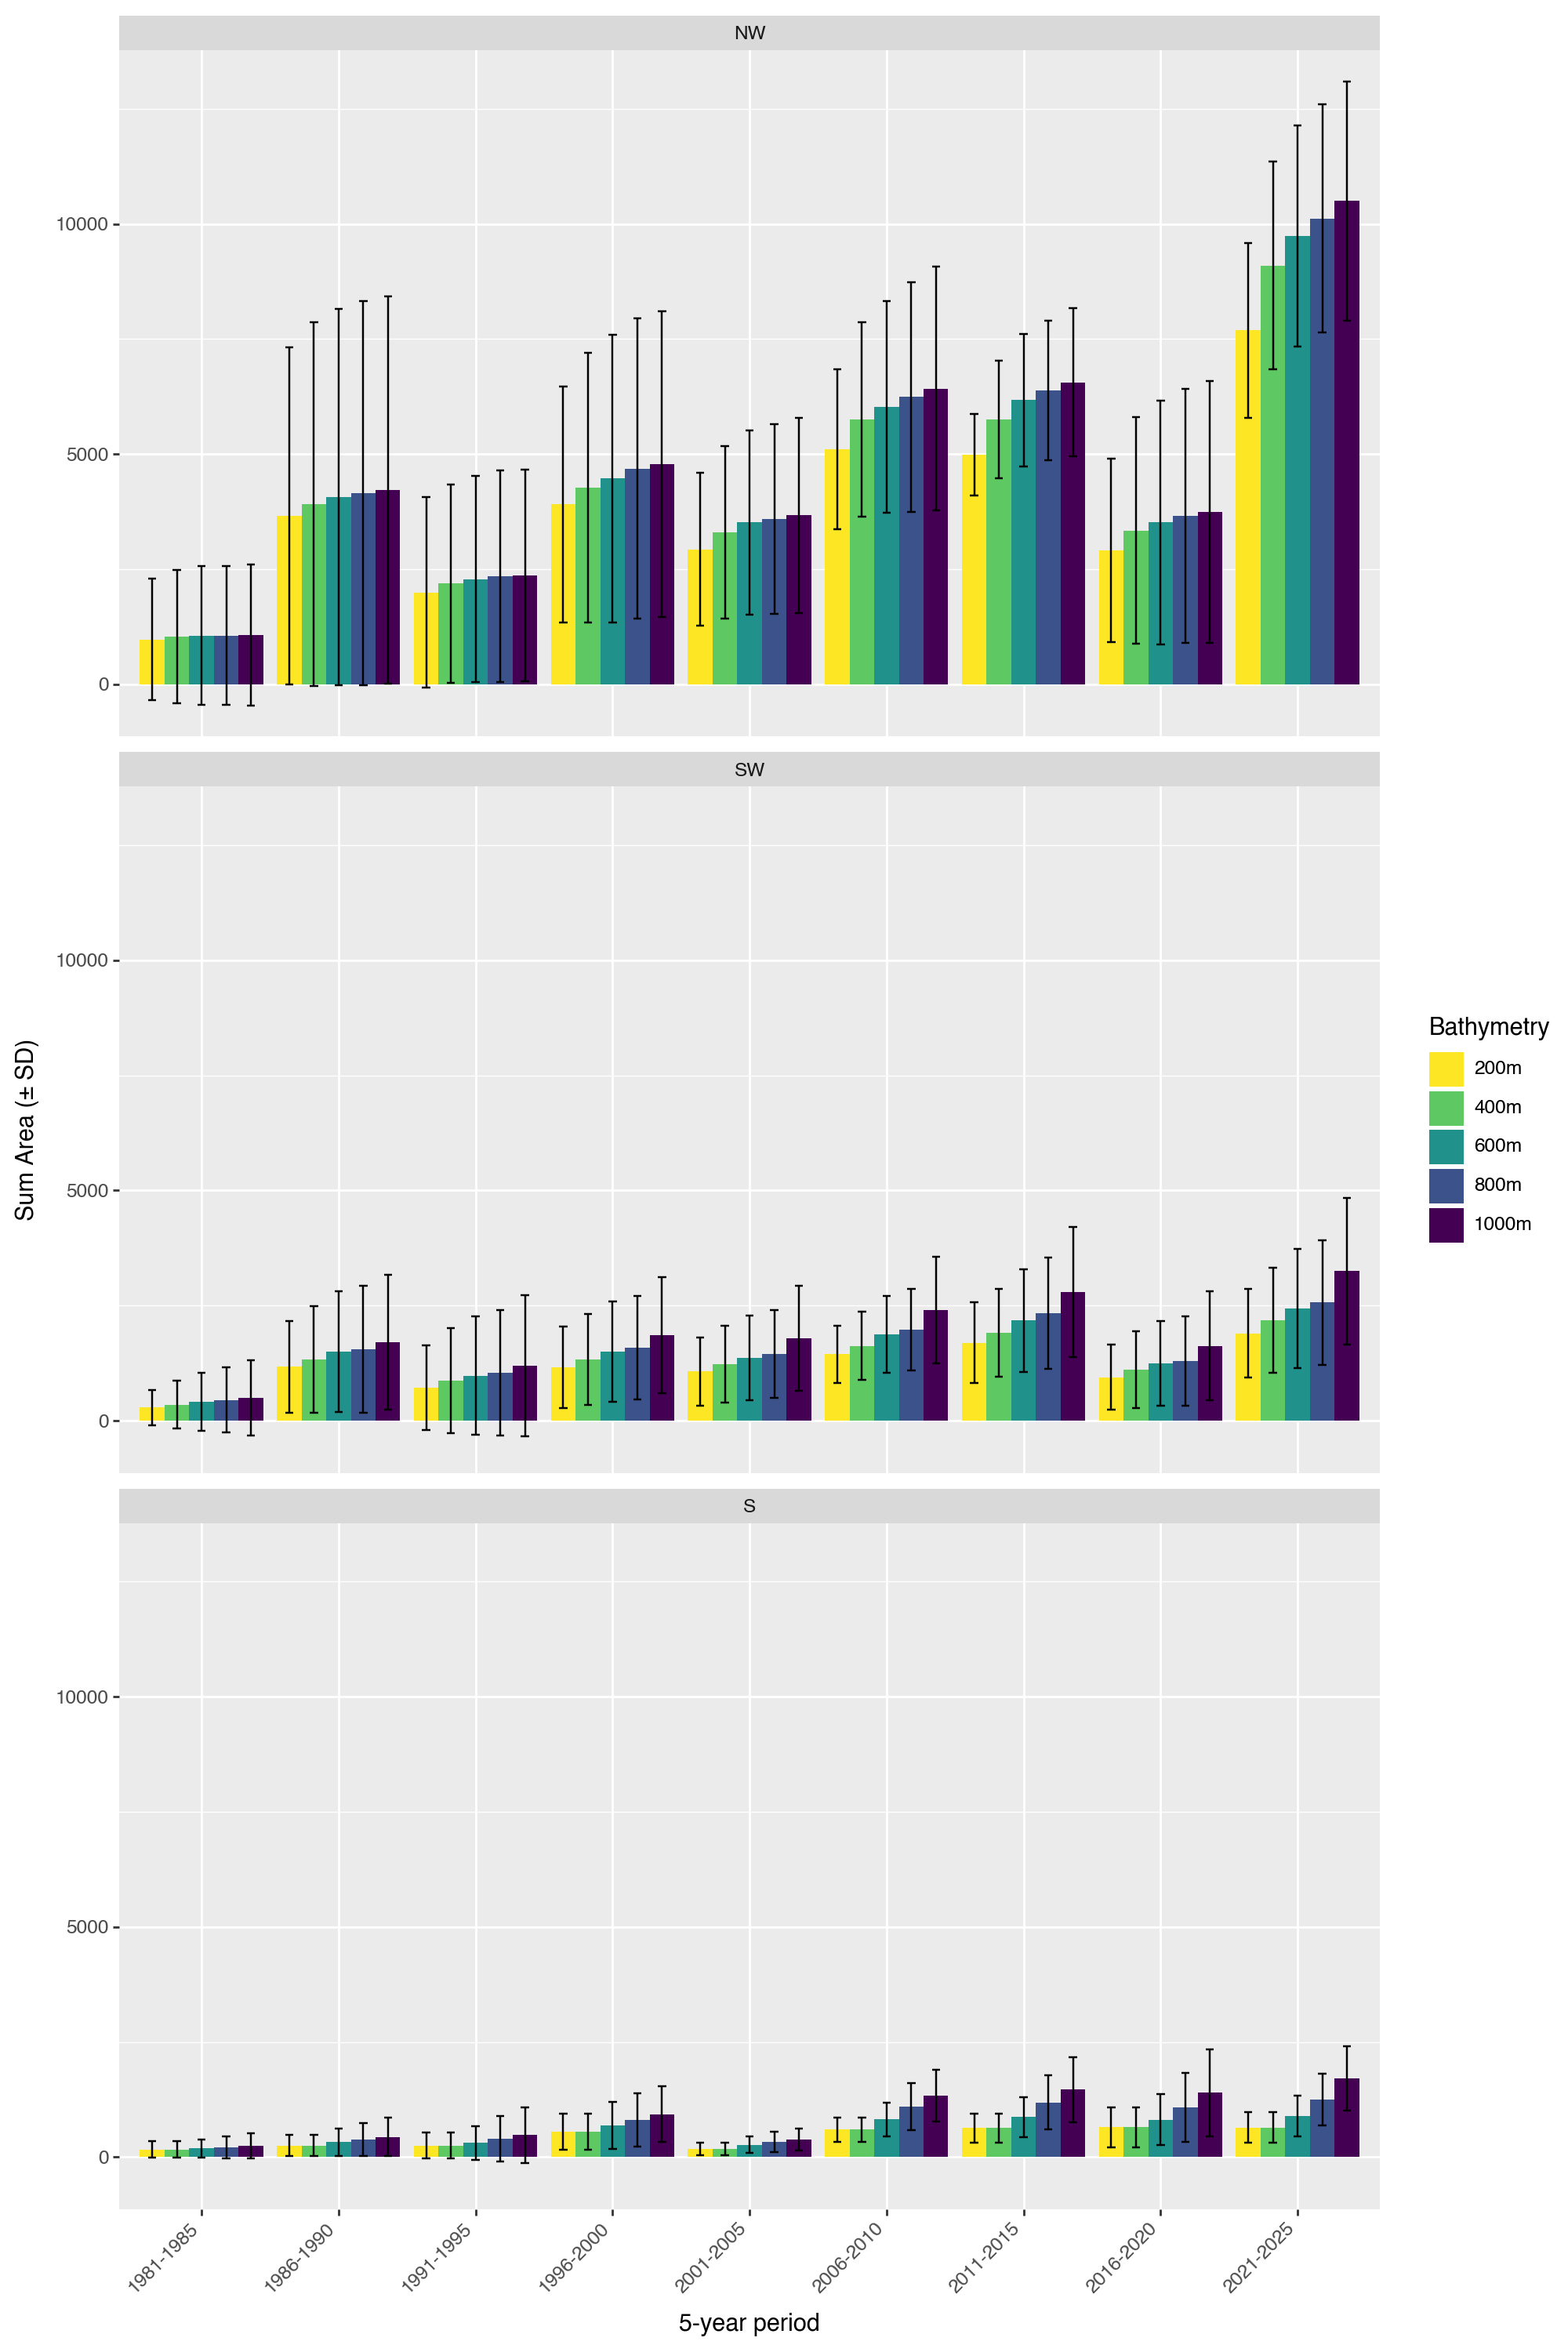

In [59]:
from plotnine import (
    ggplot, aes, geom_col, geom_errorbar, position_dodge, facet_wrap,
    scale_fill_cmap_d, labs, theme, element_text
)

# Choose what to plot
var = "sum_area_km2"
var_label = "Sum Area"
zones = ["NW", "SW", "S"]

# 5-year bins ending in 2025: 1981–1985, 1986–1990, ..., 2021–2025
combined["half_decade_start"] = ((combined["Year"] - 1) // 5) * 5 + 1
combined["half_decade"] = (
    combined["half_decade_start"].astype(str) + "-" + (combined["half_decade_start"] + 4).astype(str)
)

# Mean and SD per zone, bin and bathymetry
half_dec = (
    combined[combined["Zone"].isin(zones)]
    .groupby(["Zone", "half_decade_start", "half_decade", "bathymetry"], as_index=False)
    .agg(mean=(var, "mean"), sd=(var, "std"))
    .sort_values("half_decade_start")
)

# Panel order (NW, SW, S) and bathymetry in ascending depth order
half_dec["Zone"] = pd.Categorical(half_dec["Zone"], categories=zones, ordered=True)
depth_order = sorted(half_dec["bathymetry"].unique(), key=lambda d: int(d.rstrip("m")))
half_dec["bathymetry"] = pd.Categorical(half_dec["bathymetry"], categories=depth_order, ordered=True)

# Plot
dodge = position_dodge(width=0.9)

(
    ggplot(half_dec, aes(x="half_decade", y="mean", fill="bathymetry"))
    + geom_col(position=dodge)
    + geom_errorbar(aes(ymin="mean - sd", ymax="mean + sd"), position=dodge, width=0.3)
    + facet_wrap("~Zone", nrow=3)
    + scale_fill_cmap_d("viridis_r")
    + labs(x="5-year period", y=f"{var_label} (± SD)", fill="Bathymetry")
    + theme(
        axis_text_x=element_text(rotation=45, ha="right"),
        figure_size=(10, 15),
    )
)

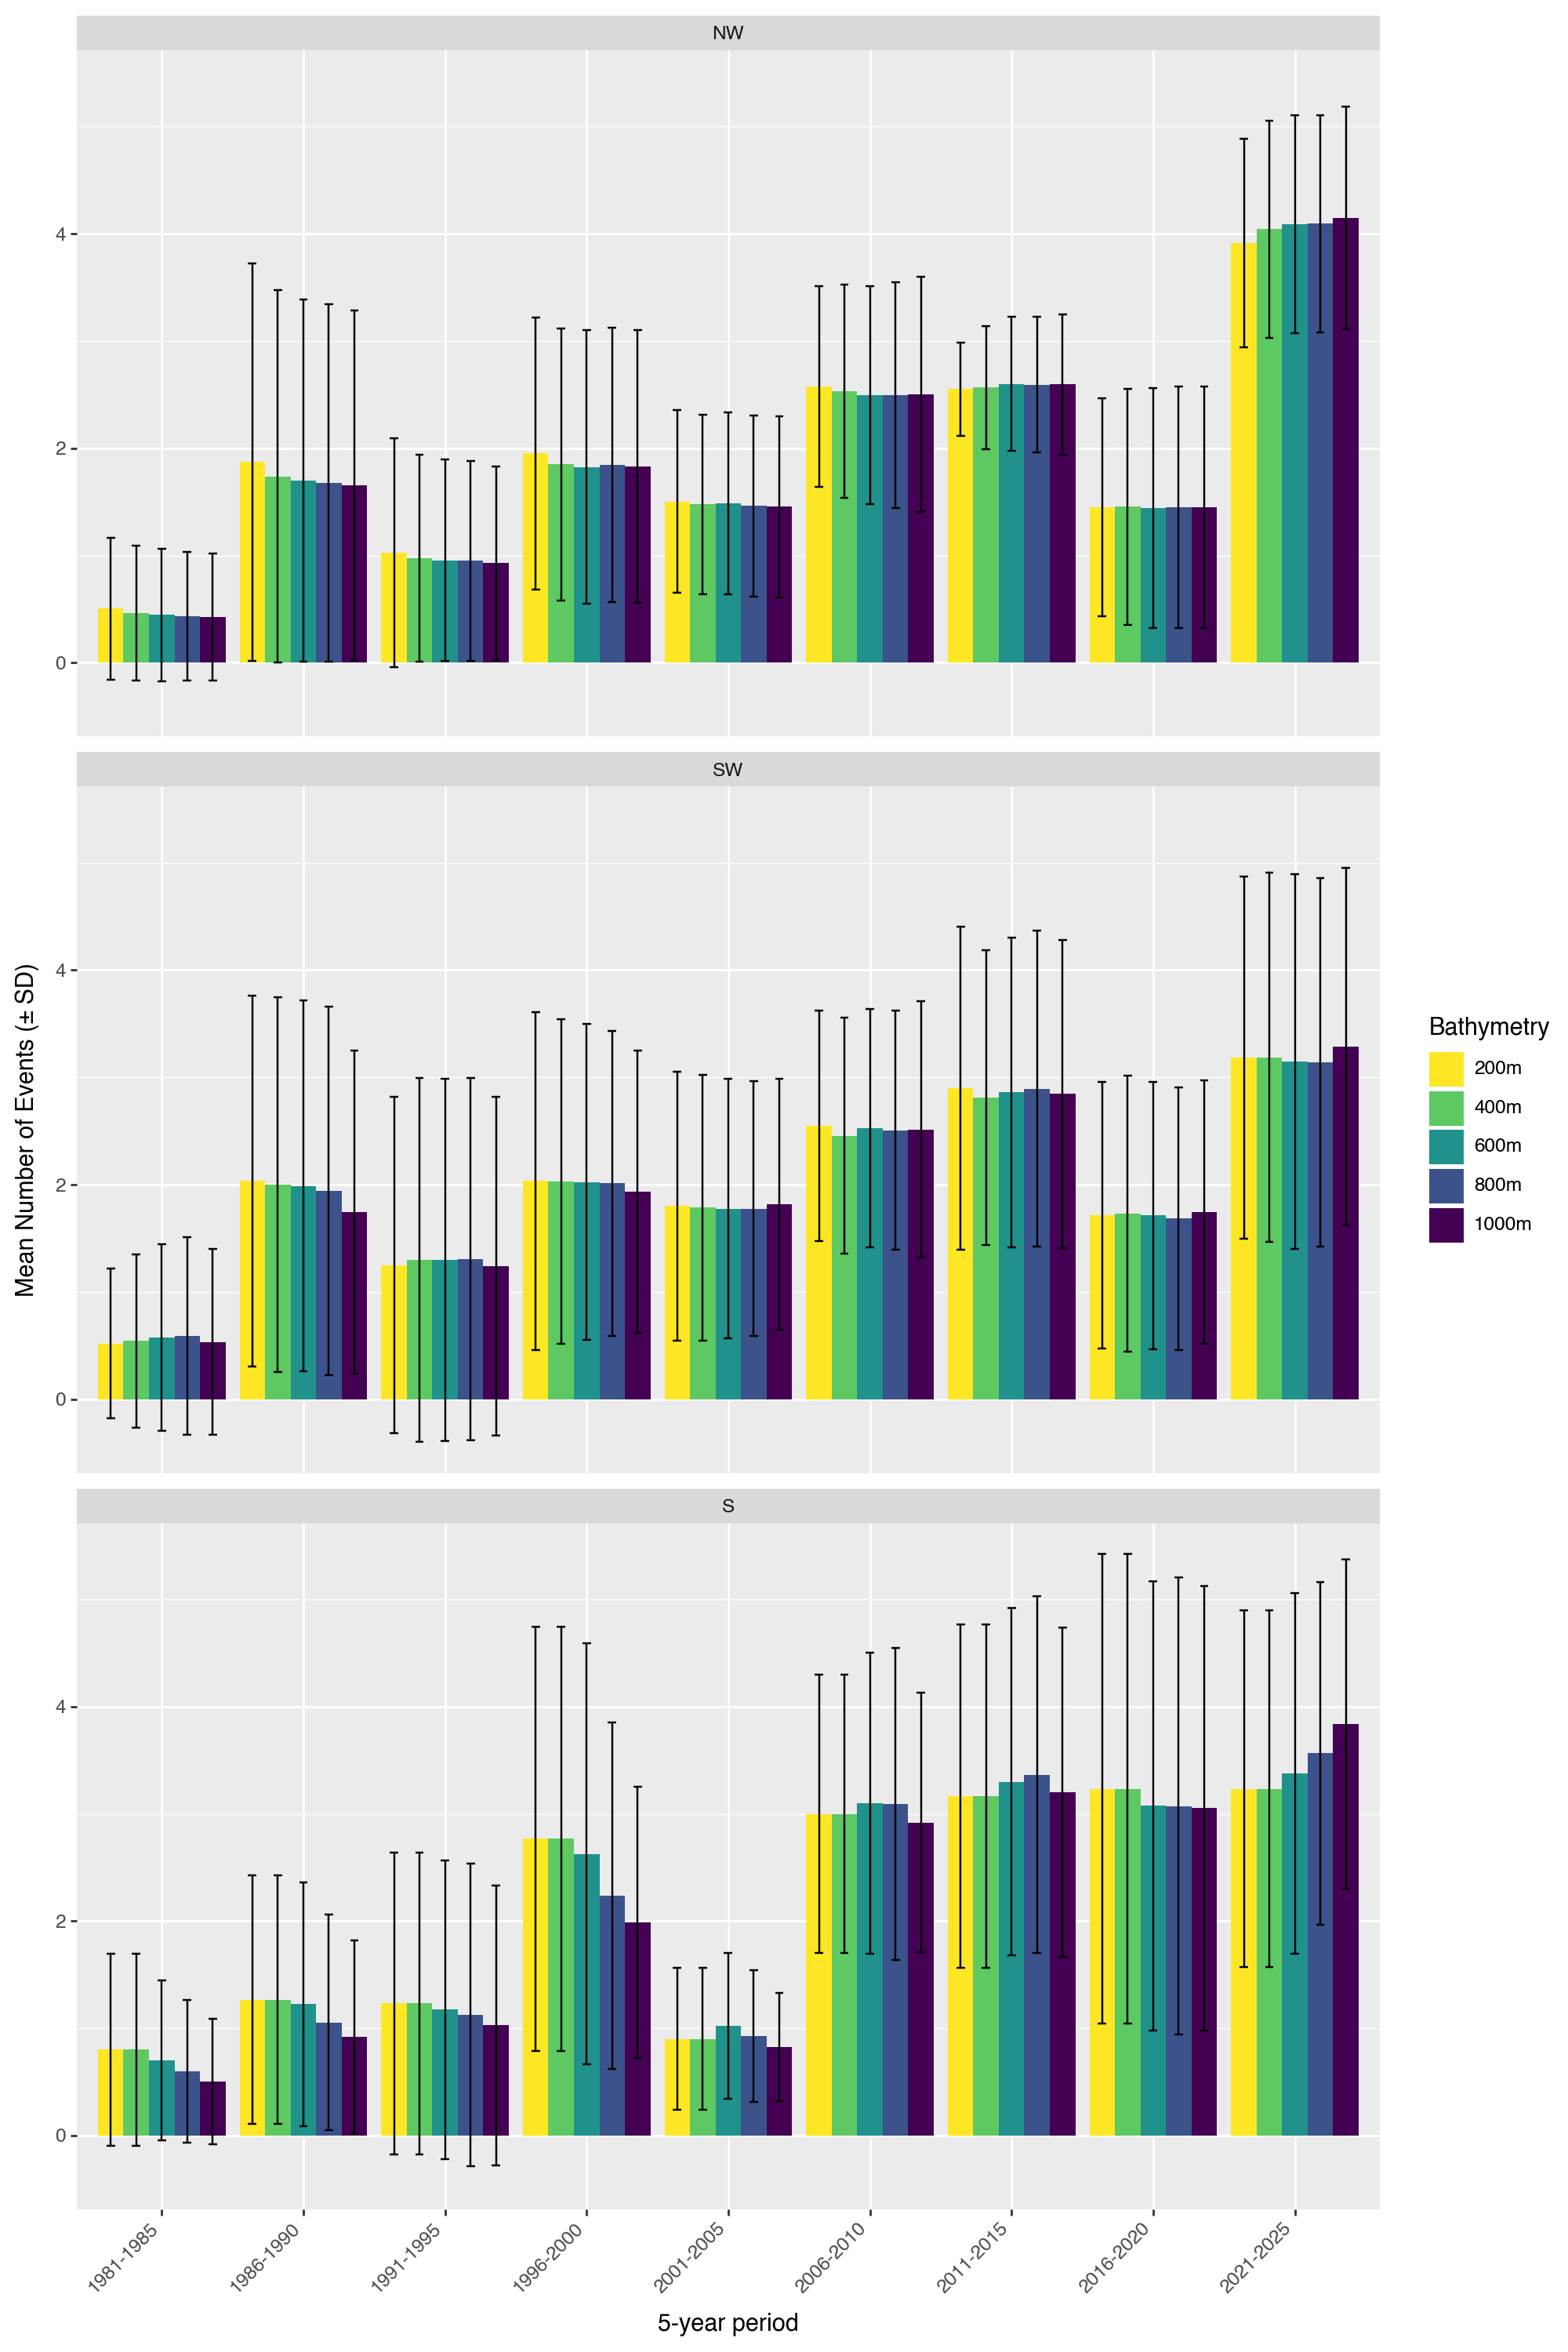

In [60]:
from plotnine import (
    ggplot, aes, geom_col, geom_errorbar, position_dodge, facet_wrap,
    scale_fill_cmap_d, labs, theme, element_text
)

# Choose what to plot
var = "mean_n_events"
var_label = "Mean Number of Events"
zones = ["NW", "SW", "S"]

# 5-year bins ending in 2025: 1981–1985, 1986–1990, ..., 2021–2025
combined["half_decade_start"] = ((combined["Year"] - 1) // 5) * 5 + 1
combined["half_decade"] = (
    combined["half_decade_start"].astype(str) + "-" + (combined["half_decade_start"] + 4).astype(str)
)

# Mean and SD per zone, bin and bathymetry
half_dec = (
    combined[combined["Zone"].isin(zones)]
    .groupby(["Zone", "half_decade_start", "half_decade", "bathymetry"], as_index=False)
    .agg(mean=(var, "mean"), sd=(var, "std"))
    .sort_values("half_decade_start")
)

# Panel order (NW, SW, S) and bathymetry in ascending depth order
half_dec["Zone"] = pd.Categorical(half_dec["Zone"], categories=zones, ordered=True)
depth_order = sorted(half_dec["bathymetry"].unique(), key=lambda d: int(d.rstrip("m")))
half_dec["bathymetry"] = pd.Categorical(half_dec["bathymetry"], categories=depth_order, ordered=True)

# Plot
dodge = position_dodge(width=0.9)

(
    ggplot(half_dec, aes(x="half_decade", y="mean", fill="bathymetry"))
    + geom_col(position=dodge)
    + geom_errorbar(aes(ymin="mean - sd", ymax="mean + sd"), position=dodge, width=0.3)
    + facet_wrap("~Zone", nrow=3)
    + scale_fill_cmap_d("viridis_r")
    + labs(x="5-year period", y=f"{var_label} (± SD)", fill="Bathymetry")
    + theme(
        axis_text_x=element_text(rotation=45, ha="right"),
        figure_size=(10, 15),
    )
)

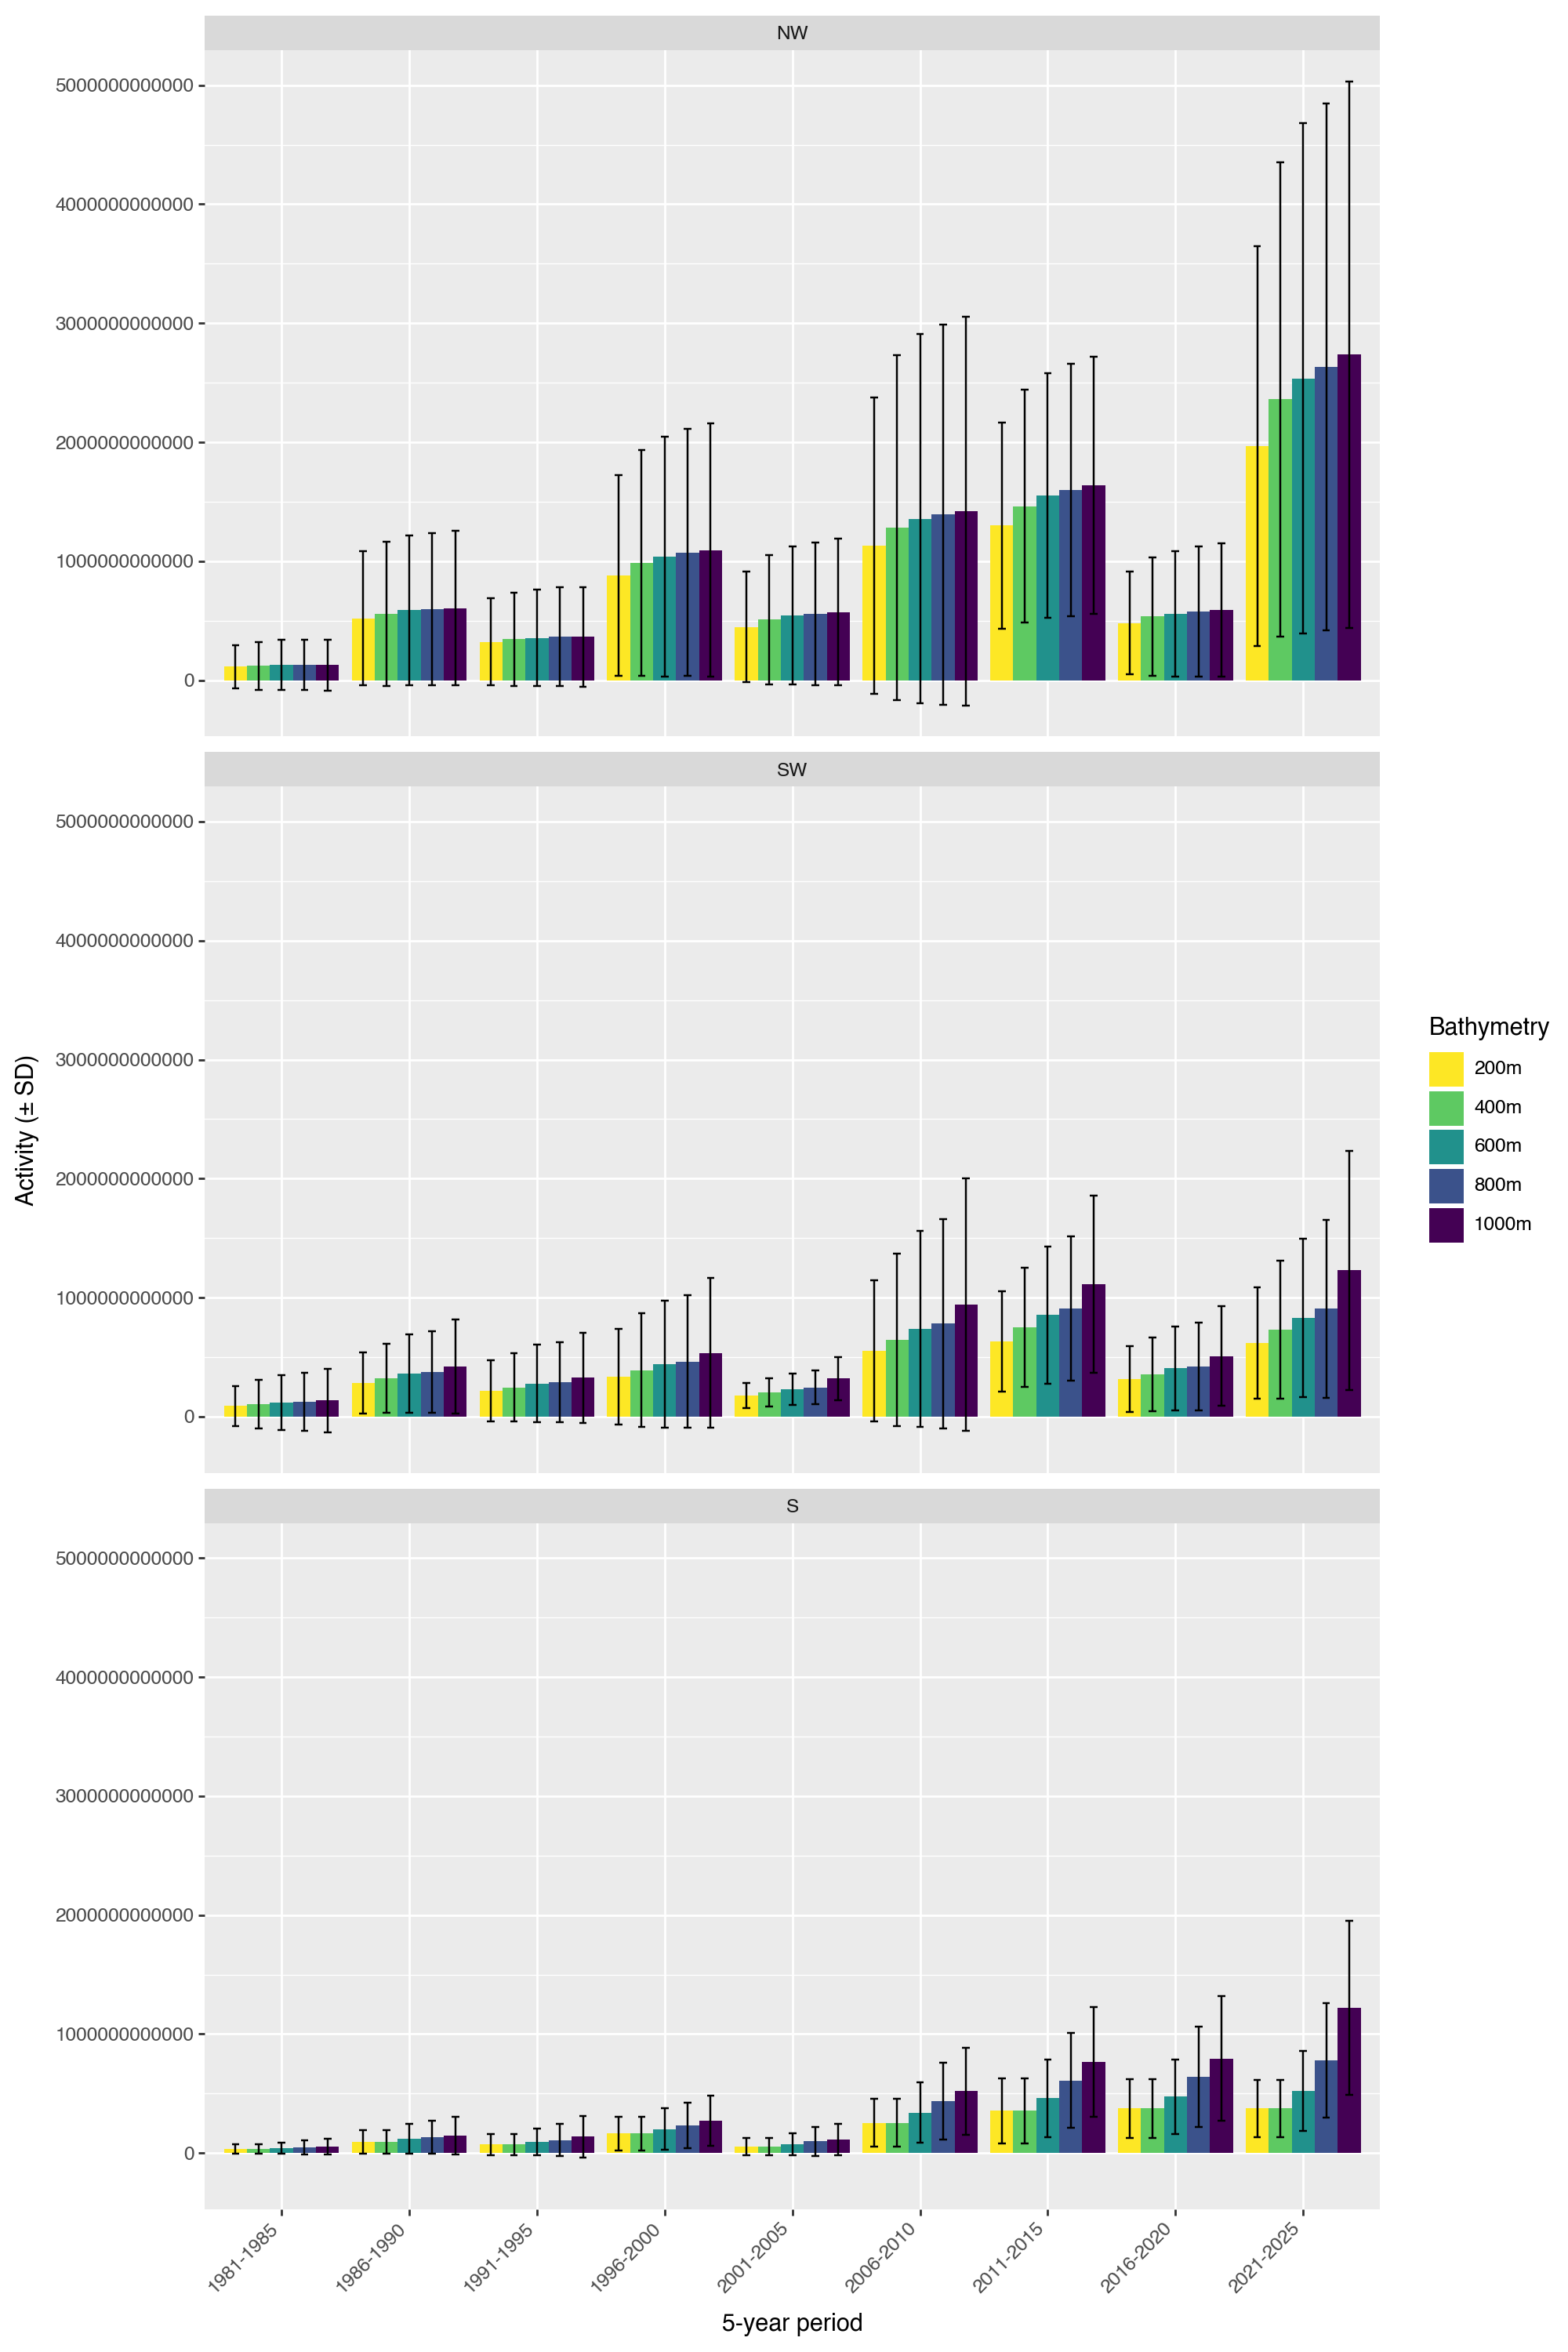

In [61]:
from plotnine import (
    ggplot, aes, geom_col, geom_errorbar, position_dodge, facet_wrap,
    scale_fill_cmap_d, labs, theme, element_text
)

# Choose what to plot
var = "activity_degC_days_m2"
var_label = "Activity"
zones = ["NW", "SW", "S"]

# 5-year bins ending in 2025: 1981–1985, 1986–1990, ..., 2021–2025
combined["half_decade_start"] = ((combined["Year"] - 1) // 5) * 5 + 1
combined["half_decade"] = (
    combined["half_decade_start"].astype(str) + "-" + (combined["half_decade_start"] + 4).astype(str)
)

# Mean and SD per zone, bin and bathymetry
half_dec = (
    combined[combined["Zone"].isin(zones)]
    .groupby(["Zone", "half_decade_start", "half_decade", "bathymetry"], as_index=False)
    .agg(mean=(var, "mean"), sd=(var, "std"))
    .sort_values("half_decade_start")
)

# Panel order (NW, SW, S) and bathymetry in ascending depth order
half_dec["Zone"] = pd.Categorical(half_dec["Zone"], categories=zones, ordered=True)
depth_order = sorted(half_dec["bathymetry"].unique(), key=lambda d: int(d.rstrip("m")))
half_dec["bathymetry"] = pd.Categorical(half_dec["bathymetry"], categories=depth_order, ordered=True)

# Plot
dodge = position_dodge(width=0.9)

(
    ggplot(half_dec, aes(x="half_decade", y="mean", fill="bathymetry"))
    + geom_col(position=dodge)
    + geom_errorbar(aes(ymin="mean - sd", ymax="mean + sd"), position=dodge, width=0.3)
    + facet_wrap("~Zone", nrow=3)
    + scale_fill_cmap_d("viridis_r")
    + labs(x="5-year period", y=f"{var_label} (± SD)", fill="Bathymetry")
    + theme(
        axis_text_x=element_text(rotation=45, ha="right"),
        figure_size=(10, 15),
    )
)